In [26]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# Project root
PROJECT_ROOT = Path.cwd().parent

# Add project root to Python path
sys.path.insert(0, str(PROJECT_ROOT))

from src.fraud_detection.data import load_data

print("Model training environment ready!")

Model training environment ready!


In [2]:
df = load_data()

print(f"Dataset shape: {df.shape}")

Dataset shape: (284807, 31)


In [3]:
X = df.drop(columns=["Class"])
y = df["Class"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (284807, 30)
Target shape: (284807,)


In [4]:
print("Target distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print((y.value_counts(normalize=True) * 100).round(4))

Target distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Target percentage:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (199364, 30)
Validation set: (42721, 30)
Test set: (42722, 30)


In [6]:
print("Fraud distribution by dataset:\n")

print("Training:")
print(y_train.value_counts())

print("\nValidation:")
print(y_val.value_counts())

print("\nTest:")
print(y_test.value_counts())

Fraud distribution by dataset:

Training:
Class
0    199020
1       344
Name: count, dtype: int64

Validation:
Class
0    42647
1       74
Name: count, dtype: int64

Test:
Class
0    42648
1       74
Name: count, dtype: int64


In [7]:
print("Fraud percentage:")
print(f"Train:      {y_train.mean() * 100:.4f}%")
print(f"Validation: {y_val.mean() * 100:.4f}%")
print(f"Test:       {y_test.mean() * 100:.4f}%")

Fraud percentage:
Train:      0.1725%
Validation: 0.1732%
Test:       0.1732%


In [8]:
logistic_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression pipeline created!")

Logistic Regression pipeline created!


In [9]:
print("Training Logistic Regression...")

logistic_pipeline.fit(X_train, y_train)

print("Training completed!")

Training Logistic Regression...
Training completed!


In [10]:
smote = logistic_pipeline.named_steps["smote"]

print("Original training samples:")
print(y_train.value_counts())

print("\nTraining samples after SMOTE:")
print(pd.Series(
    smote.fit_resample(
        logistic_pipeline.named_steps["scaler"].transform(X_train),
        y_train
    )[1]
).value_counts())

Original training samples:
Class
0    199020
1       344
Name: count, dtype: int64

Training samples after SMOTE:
Class
0    199020
1    199020
Name: count, dtype: int64


In [11]:
y_val_pred = logistic_pipeline.predict(X_val)

y_val_proba = logistic_pipeline.predict_proba(X_val)[:, 1]

print("Validation predictions generated!")

Validation predictions generated!


In [12]:
precision = precision_score(y_val, y_val_pred)
recall = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)
roc_auc = roc_auc_score(y_val, y_val_proba)
pr_auc = average_precision_score(y_val, y_val_proba)

print("Logistic Regression — Validation Results")
print("-----------------------------------------")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

Logistic Regression — Validation Results
-----------------------------------------
Precision : 0.0654
Recall    : 0.8784
F1 Score  : 0.1217
ROC-AUC   : 0.9669
PR-AUC    : 0.6315


In [13]:
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Legitimate", "Fraud"]
    )
)

              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     42647
       Fraud       0.07      0.88      0.12        74

    accuracy                           0.98     42721
   macro avg       0.53      0.93      0.56     42721
weighted avg       1.00      0.98      0.99     42721



In [14]:
cm = confusion_matrix(y_val, y_val_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[41718   929]
 [    9    65]]


In [16]:
rf_pipeline = Pipeline(
    steps=[
        ("smote", SMOTE(random_state=42)),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=None,
                min_samples_split=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created!")

Random Forest pipeline created!


In [17]:
print("Training Random Forest...")

rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed!")

Training Random Forest...
Random Forest training completed!


In [18]:
y_val_pred_rf = rf_pipeline.predict(X_val)

y_val_proba_rf = rf_pipeline.predict_proba(X_val)[:, 1]

print("Random Forest validation predictions generated!")

Random Forest validation predictions generated!


In [19]:
precision_rf = precision_score(y_val, y_val_pred_rf)
recall_rf = recall_score(y_val, y_val_pred_rf)
f1_rf = f1_score(y_val, y_val_pred_rf)
roc_auc_rf = roc_auc_score(y_val, y_val_proba_rf)
pr_auc_rf = average_precision_score(y_val, y_val_proba_rf)

print("Random Forest — Validation Results")
print("----------------------------------")
print(f"Precision : {precision_rf:.4f}")
print(f"Recall    : {recall_rf:.4f}")
print(f"F1 Score  : {f1_rf:.4f}")
print(f"ROC-AUC   : {roc_auc_rf:.4f}")
print(f"PR-AUC    : {pr_auc_rf:.4f}")

Random Forest — Validation Results
----------------------------------
Precision : 0.8485
Recall    : 0.7568
F1 Score  : 0.8000
ROC-AUC   : 0.9646
PR-AUC    : 0.8208


In [20]:
print(
    classification_report(
        y_val,
        y_val_pred_rf,
        target_names=["Legitimate", "Fraud"]
    )
)

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42647
       Fraud       0.85      0.76      0.80        74

    accuracy                           1.00     42721
   macro avg       0.92      0.88      0.90     42721
weighted avg       1.00      1.00      1.00     42721



In [21]:
cm_rf = confusion_matrix(y_val, y_val_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

Random Forest Confusion Matrix:
[[42637    10]
 [   18    56]]


In [22]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Precision": [
        precision,
        precision_rf
    ],
    "Recall": [
        recall,
        recall_rf
    ],
    "F1 Score": [
        f1,
        f1_rf
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_rf
    ],
    "PR-AUC": [
        pr_auc,
        pr_auc_rf
    ]
})

comparison

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.065392,0.878378,0.121723,0.966926,0.631459
1,Random Forest,0.848485,0.756757,0.800000,0.964623,0.820782


In [23]:
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_val_proba_rf >= threshold).astype(int)

    precision_t = precision_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    recall_t = recall_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    f1_t = f1_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_t,
        "Recall": recall_t,
        "F1 Score": f1_t
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1 Score
0,0.10,0.318182,0.851351,0.463235
1,0.15,0.430556,0.837838,0.568807
2,0.20,0.570093,0.824324,0.674033
3,0.25,0.642105,0.824324,0.721893
4,0.30,0.701149,0.824324,0.757764
5,0.35,0.740741,0.810811,0.774194
6,0.40,0.756410,0.797297,0.776316
7,0.45,0.808219,0.797297,0.802721
8,0.50,0.848485,0.756757,0.800000
9,0.55,0.887097,0.743243,0.808824


In [24]:
best_f1_row = threshold_df.loc[
    threshold_df["F1 Score"].idxmax()
]

print("Best F1 threshold:")
print(best_f1_row)

Best F1 threshold:
Threshold    0.700000
Precision    0.915254
Recall       0.729730
F1 Score     0.812030
Name: 12, dtype: float64


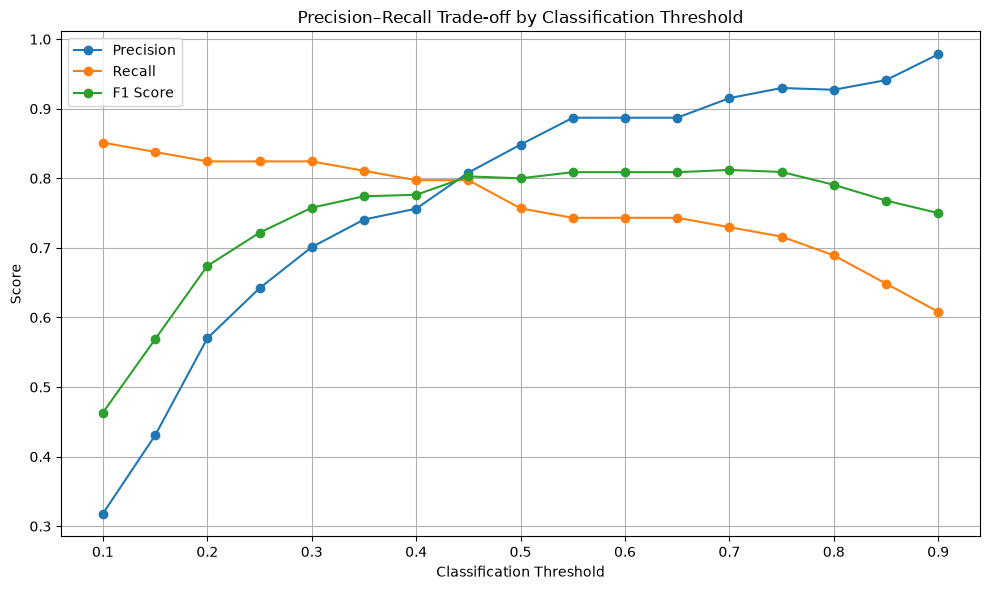

In [27]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision–Recall Trade-off by Classification Threshold")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [28]:
recall_target = 0.85

eligible_thresholds = threshold_df[
    threshold_df["Recall"] >= recall_target
]

if len(eligible_thresholds) > 0:
    best_recall_threshold = eligible_thresholds.loc[
        eligible_thresholds["Precision"].idxmax()
    ]

    print("Best threshold with at least 85% recall:")
    print(best_recall_threshold)
else:
    print("No threshold achieved 85% recall.")

Best threshold with at least 85% recall:
Threshold    0.100000
Precision    0.318182
Recall       0.851351
F1 Score     0.463235
Name: 0, dtype: float64


In [29]:
BEST_THRESHOLD = 0.70

y_test_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

print("Test probabilities generated.")

Test probabilities generated.


In [30]:
y_test_pred_rf = (
    y_test_proba_rf >= BEST_THRESHOLD
).astype(int)

print(f"Threshold used: {BEST_THRESHOLD}")

Threshold used: 0.7


In [31]:
precision_test = precision_score(
    y_test,
    y_test_pred_rf
)

recall_test = recall_score(
    y_test,
    y_test_pred_rf
)

f1_test = f1_score(
    y_test,
    y_test_pred_rf
)

roc_auc_test = roc_auc_score(
    y_test,
    y_test_proba_rf
)

pr_auc_test = average_precision_score(
    y_test,
    y_test_proba_rf
)

print("FINAL RANDOM FOREST — TEST RESULTS")
print("-----------------------------------")
print(f"Threshold : {BEST_THRESHOLD:.2f}")
print(f"Precision : {precision_test:.4f}")
print(f"Recall    : {recall_test:.4f}")
print(f"F1 Score  : {f1_test:.4f}")
print(f"ROC-AUC   : {roc_auc_test:.4f}")
print(f"PR-AUC    : {pr_auc_test:.4f}")

FINAL RANDOM FOREST — TEST RESULTS
-----------------------------------
Threshold : 0.70
Precision : 0.9508
Recall    : 0.7838
F1 Score  : 0.8593
ROC-AUC   : 0.9692
PR-AUC    : 0.8428


In [32]:
cm_test = confusion_matrix(
    y_test,
    y_test_pred_rf
)

print("Final Test Confusion Matrix:")
print(cm_test)

Final Test Confusion Matrix:
[[42645     3]
 [   16    58]]


In [33]:
print(
    classification_report(
        y_test,
        y_test_pred_rf,
        target_names=["Legitimate", "Fraud"]
    )
)

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42648
       Fraud       0.95      0.78      0.86        74

    accuracy                           1.00     42722
   macro avg       0.98      0.89      0.93     42722
weighted avg       1.00      1.00      1.00     42722



In [34]:
tn, fp, fn, tp = cm_test.ravel()

false_positive_rate = fp / (fp + tn)
false_negative_rate = fn / (fn + tp)

print(f"False Positive Rate : {false_positive_rate:.4%}")
print(f"False Negative Rate : {false_negative_rate:.4%}")
print(f"True Positives       : {tp}")
print(f"False Negatives      : {fn}")
print(f"False Positives      : {fp}")
print(f"True Negatives       : {tn}")

False Positive Rate : 0.0070%
False Negative Rate : 21.6216%
True Positives       : 58
False Negatives      : 16
False Positives      : 3
True Negatives       : 42645


In [35]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_pipeline.named_steps["model"].feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
14,V14,0.201067
10,V10,0.128737
4,V4,0.128198
12,V12,0.104487
17,V17,0.094300
3,V3,0.071136
16,V16,0.055993
11,V11,0.044323
2,V2,0.030711
9,V9,0.019715


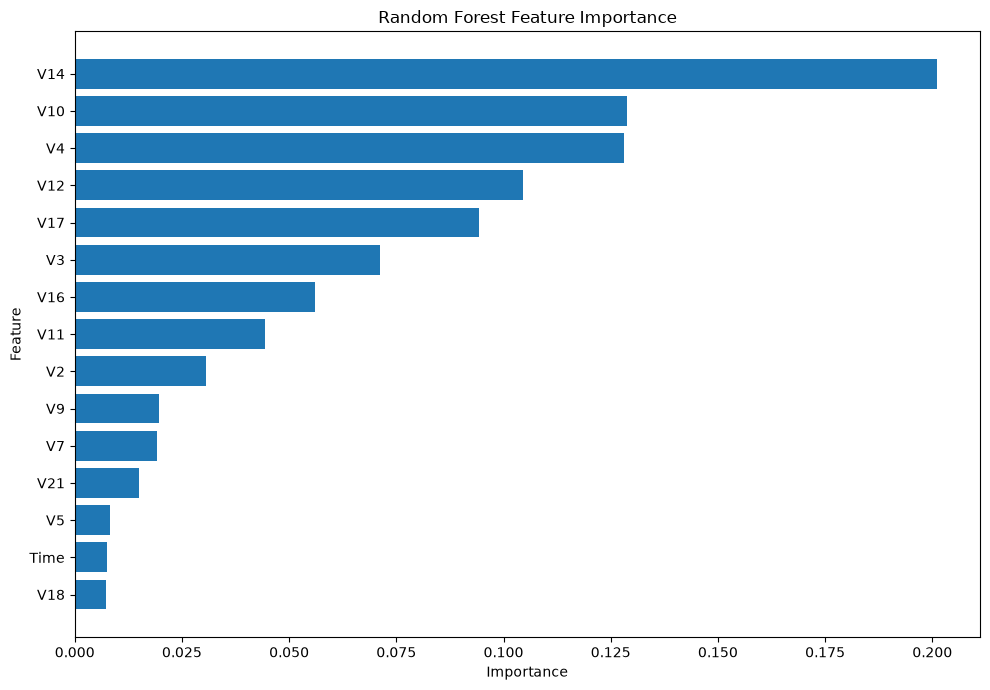

In [36]:
top_importance = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_importance["Feature"][::-1],
    top_importance["Importance"][::-1]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [39]:
from src.fraud_detection.config import METRICS_DIR

METRICS_DIR.mkdir(parents=True, exist_ok=True)

feature_importance.to_csv(
    METRICS_DIR / "feature_importance.csv",
    index=False
)

print("Feature importance saved.")

Feature importance saved.


In [40]:
import shap

print("SHAP is ready!")
print("Version:", shap.__version__)

SHAP is ready!
Version: 0.52.0


In [41]:
X_shap = X_test.sample(
    n=1000,
    random_state=42
)

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (1000, 30)


In [42]:
rf_model = rf_pipeline.named_steps["model"]

explainer = shap.TreeExplainer(rf_model)

print("SHAP TreeExplainer created!")

SHAP TreeExplainer created!


In [43]:
shap_explanation = explainer(X_shap)

print("SHAP values calculated!")
print("SHAP shape:", shap_explanation.values.shape)

SHAP values calculated!
SHAP shape: (1000, 30, 2)


In [44]:
shap_values = shap_explanation.values

if shap_values.ndim == 3:
    shap_values_fraud = shap_values[:, :, 1]
else:
    shap_values_fraud = shap_values

print("Fraud SHAP shape:", shap_values_fraud.shape)

Fraud SHAP shape: (1000, 30)


In [45]:
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values_fraud).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

shap_importance.head(15)

,Feature,Mean_Absolute_SHAP
14,V14,0.088175
4,V4,0.087826
12,V12,0.076109
10,V10,0.052452
3,V3,0.043323
11,V11,0.037016
17,V17,0.034155
16,V16,0.026911
7,V7,0.010494
1,V1,0.009289


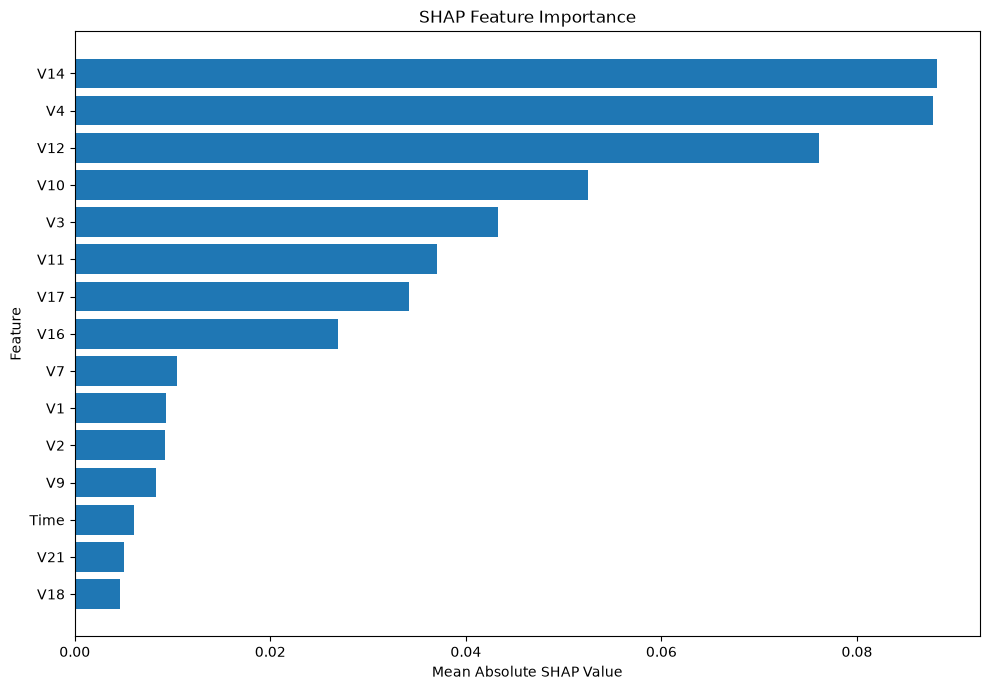

In [46]:
top_shap = shap_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_shap["Feature"][::-1],
    top_shap["Mean_Absolute_SHAP"][::-1]
)

plt.title("SHAP Feature Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [47]:
shap_importance.to_csv(
    METRICS_DIR / "shap_feature_importance.csv",
    index=False
)

print("SHAP feature importance saved.")

SHAP feature importance saved.


In [48]:
shap_sample_probabilities = rf_pipeline.predict_proba(
    X_shap
)[:, 1]

highest_risk_position = np.argmax(
    shap_sample_probabilities
)

highest_risk_probability = shap_sample_probabilities[
    highest_risk_position
]

print(f"Highest predicted fraud probability: {highest_risk_probability:.4%}")

Highest predicted fraud probability: 100.0000%


In [49]:
transaction_to_explain = X_shap.iloc[
    highest_risk_position
]

print("Transaction features:")
display(transaction_to_explain.to_frame(name="Value"))

Transaction features:


,Value
Time,7551.000000
V1,0.316459
V2,3.809076
V3,-5.615159
V4,6.047445
V5,1.554026
V6,-2.651353
V7,-0.746579
V8,0.055586
V9,-2.678679


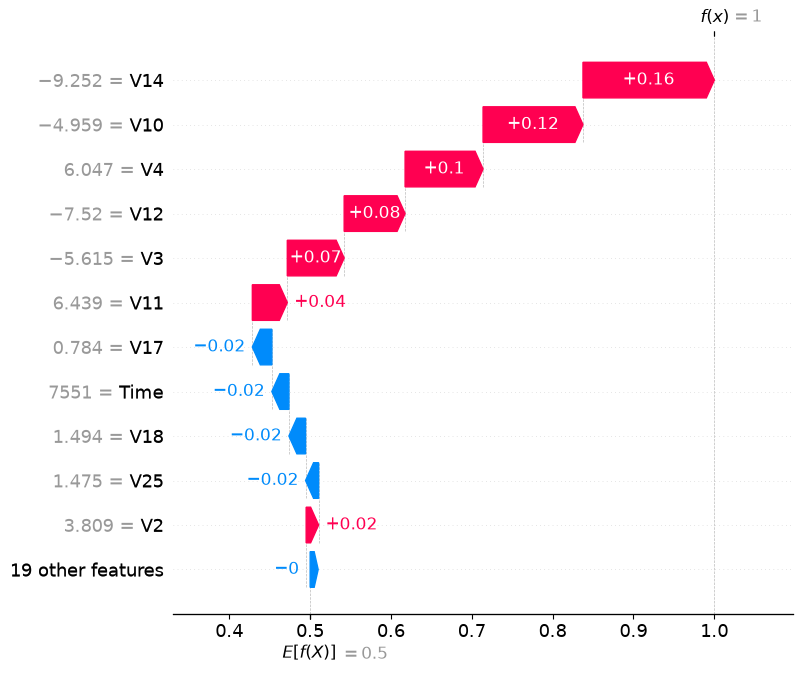

In [50]:
base_values = shap_explanation.base_values

if np.ndim(base_values) == 2:
    base_value = base_values[highest_risk_position, 1]
else:
    base_value = base_values[highest_risk_position]

individual_explanation = shap.Explanation(
    values=shap_values_fraud[highest_risk_position],
    base_values=base_value,
    data=transaction_to_explain.values,
    feature_names=X_shap.columns.tolist()
)

shap.plots.waterfall(
    individual_explanation,
    max_display=12
)

In [51]:
import joblib

print("Joblib ready!")

Joblib ready!


In [52]:
from src.fraud_detection.config import MODEL_DIR

MODEL_DIR.mkdir(parents=True, exist_ok=True)

print(f"Model directory: {MODEL_DIR}")

Model directory: C:\Data Science Projects\Credit Card Fraud Detection\models


In [53]:
model_bundle = {
    "model": rf_pipeline,
    "threshold": BEST_THRESHOLD,
    "features": X_train.columns.tolist(),
    "model_name": "Random Forest",
    "validation_metrics": {
        "precision": precision_rf,
        "recall": recall_rf,
        "f1_score": f1_rf,
        "roc_auc": roc_auc_rf,
        "pr_auc": pr_auc_rf
    },
    "test_metrics": {
        "precision": precision_test,
        "recall": recall_test,
        "f1_score": f1_test,
        "roc_auc": roc_auc_test,
        "pr_auc": pr_auc_test
    }
}

print("Model bundle created.")

Model bundle created.


In [54]:
model_path = MODEL_DIR / "fraud_model.joblib"

joblib.dump(
    model_bundle,
    model_path
)

print(f"Model saved successfully to:\n{model_path}")

Model saved successfully to:
C:\Data Science Projects\Credit Card Fraud Detection\models\fraud_model.joblib


In [55]:
loaded_bundle = joblib.load(model_path)

print("Model loaded successfully!")
print("Model:", loaded_bundle["model_name"])
print("Threshold:", loaded_bundle["threshold"])
print("Number of features:", len(loaded_bundle["features"]))

Model loaded successfully!
Model: Random Forest
Threshold: 0.7
Number of features: 30


In [57]:
loaded_model = loaded_bundle["model"]
loaded_threshold = loaded_bundle["threshold"]

sample_transaction = X_test.iloc[[0]]

sample_probability = loaded_model.predict_proba(
    sample_transaction
)[0, 1]

sample_prediction = int(
    sample_probability >= loaded_threshold
)

print(f"Fraud probability: {sample_probability:.4%}")
print(f"Prediction: {sample_prediction}")

Fraud probability: 0.0000%
Prediction: 0


In [58]:
from src.fraud_detection.models import (
    load_model_bundle,
    predict_transaction
)

print("Prediction module imported successfully!")

Prediction module imported successfully!


In [59]:
model_bundle = load_model_bundle()

print("Saved model loaded!")
print("Model:", model_bundle["model_name"])
print("Threshold:", model_bundle["threshold"])
print("Features:", len(model_bundle["features"]))

Saved model loaded!
Model: Random Forest
Threshold: 0.7
Features: 30


In [60]:
model_bundle = load_model_bundle()

print("Saved model loaded!")
print("Model:", model_bundle["model_name"])
print("Threshold:", model_bundle["threshold"])
print("Features:", len(model_bundle["features"]))

Saved model loaded!
Model: Random Forest
Threshold: 0.7
Features: 30


In [61]:
sample_transaction = X_test.iloc[[0]]

prediction_result = predict_transaction(
    sample_transaction,
    model_bundle
)

prediction_result

,fraud_probability,prediction,status,risk_level,recommended_action
0,0.0,0,Legitimate,Low,Allow transaction


In [62]:
sample_batch = X_test.iloc[:10]

batch_results = predict_transaction(
    sample_batch,
    model_bundle
)

batch_results

,fraud_probability,prediction,status,risk_level,recommended_action
0,0.000,0,Legitimate,Low,Allow transaction
1,0.005,0,Legitimate,Low,Allow transaction
2,0.000,0,Legitimate,Low,Allow transaction
3,0.000,0,Legitimate,Low,Allow transaction
4,0.000,0,Legitimate,Low,Allow transaction
5,0.000,0,Legitimate,Low,Allow transaction
6,0.010,0,Legitimate,Low,Allow transaction
7,0.000,0,Legitimate,Low,Allow transaction
8,0.000,0,Legitimate,Low,Allow transaction
9,0.000,0,Legitimate,Low,Allow transaction


In [63]:
print("Prediction summary:")
print(
    batch_results["status"].value_counts()
)

print("\nRisk summary:")
print(
    batch_results["risk_level"].value_counts()
)

Prediction summary:
status
Legitimate    10
Name: count, dtype: int64

Risk summary:
risk_level
Low    10
Name: count, dtype: int64


In [64]:
api_test_transaction = X_test.iloc[0].to_dict()

api_test_transaction

{'Time': 148580.0,
 'V1': -1.08860252327554,
 'V2': 0.227684493717604,
 'V3': 1.70446423633482,
 'V4': -2.35333183593795,
 'V5': -0.0205756088947456,
 'V6': -0.172106743175544,
 'V7': 0.583031671396642,
 'V8': 0.0617329021383216,
 'V9': 0.239968628337737,
 'V10': -1.31502430302492,
 'V11': 0.656777603828121,
 'V12': 0.764813769585199,
 'V13': 0.407951980688857,
 'V14': -0.156424317805708,
 'V15': -0.0674871993672851,
 'V16': 0.631197952122071,
 'V17': -1.08135240543906,
 'V18': 0.632738493297563,
 'V19': -0.121099129343154,
 'V20': -0.0738035734416213,
 'V21': 0.217620686602102,
 'V22': 0.653238021876026,
 'V23': -0.327775067273328,
 'V24': -0.315683709621901,
 'V25': 0.583261642757641,
 'V26': 0.743449612737544,
 'V27': -0.120431966266262,
 'V28': 0.0051651175831809,
 'Amount': 60.0}

In [65]:
import json

api_payload = {
    "features": api_test_transaction
}

print(
    json.dumps(
        api_payload,
        indent=2
    )
)

{
  "features": {
    "Time": 148580.0,
    "V1": -1.08860252327554,
    "V2": 0.227684493717604,
    "V3": 1.70446423633482,
    "V4": -2.35333183593795,
    "V5": -0.0205756088947456,
    "V6": -0.172106743175544,
    "V7": 0.583031671396642,
    "V8": 0.0617329021383216,
    "V9": 0.239968628337737,
    "V10": -1.31502430302492,
    "V11": 0.656777603828121,
    "V12": 0.764813769585199,
    "V13": 0.407951980688857,
    "V14": -0.156424317805708,
    "V15": -0.0674871993672851,
    "V16": 0.631197952122071,
    "V17": -1.08135240543906,
    "V18": 0.632738493297563,
    "V19": -0.121099129343154,
    "V20": -0.0738035734416213,
    "V21": 0.217620686602102,
    "V22": 0.653238021876026,
    "V23": -0.327775067273328,
    "V24": -0.315683709621901,
    "V25": 0.583261642757641,
    "V26": 0.743449612737544,
    "V27": -0.120431966266262,
    "V28": 0.0051651175831809,
    "Amount": 60.0
  }
}


In [66]:
print(json.dumps(api_payload))

{"features": {"Time": 148580.0, "V1": -1.08860252327554, "V2": 0.227684493717604, "V3": 1.70446423633482, "V4": -2.35333183593795, "V5": -0.0205756088947456, "V6": -0.172106743175544, "V7": 0.583031671396642, "V8": 0.0617329021383216, "V9": 0.239968628337737, "V10": -1.31502430302492, "V11": 0.656777603828121, "V12": 0.764813769585199, "V13": 0.407951980688857, "V14": -0.156424317805708, "V15": -0.0674871993672851, "V16": 0.631197952122071, "V17": -1.08135240543906, "V18": 0.632738493297563, "V19": -0.121099129343154, "V20": -0.0738035734416213, "V21": 0.217620686602102, "V22": 0.653238021876026, "V23": -0.327775067273328, "V24": -0.315683709621901, "V25": 0.583261642757641, "V26": 0.743449612737544, "V27": -0.120431966266262, "V28": 0.0051651175831809, "Amount": 60.0}}


# Evaluation Artifacts

Generate and save evaluation artifacts for the FraudGuard dashboard.

Confusion Matrix:
[[42647     1]
 [   28    46]]

True Negatives : 42647
False Positives: 1
False Negatives: 28
True Positives : 46


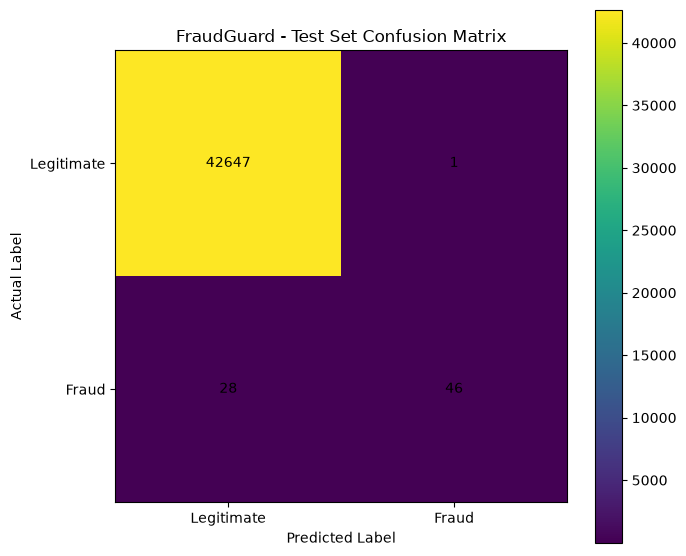

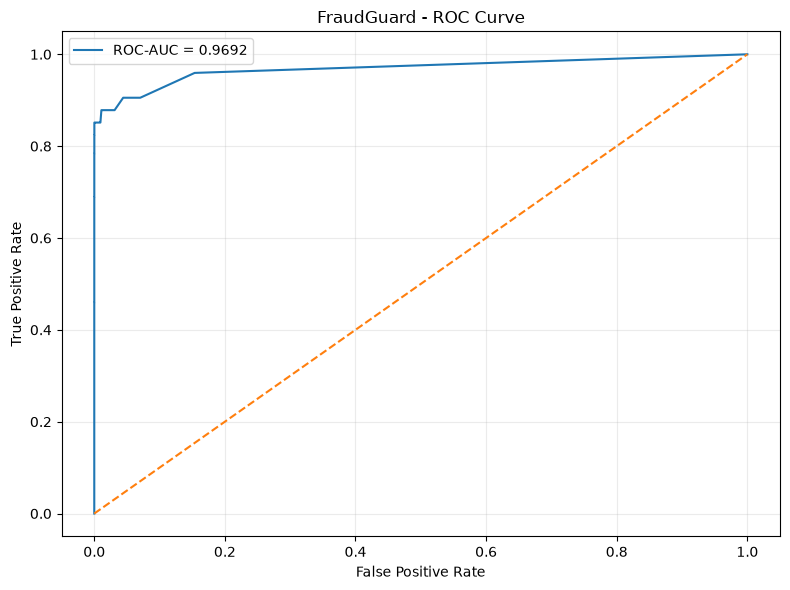

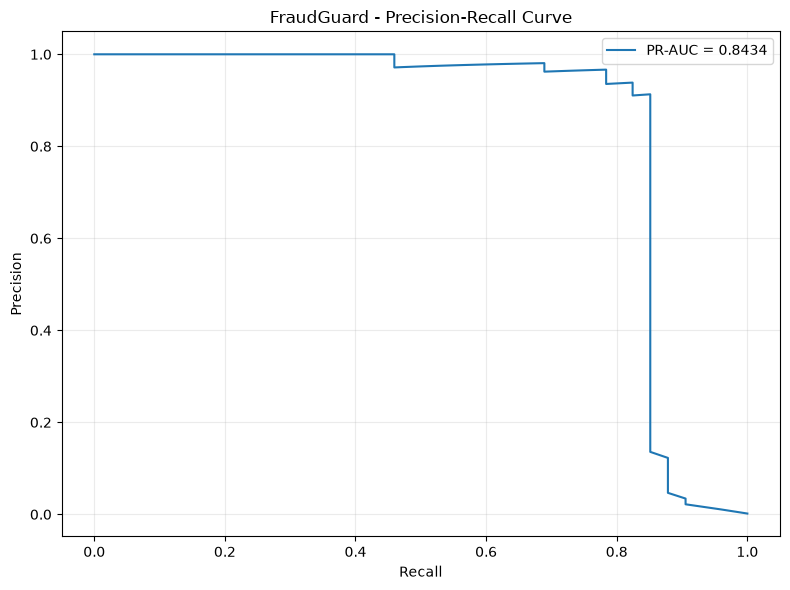


EVALUATION ARTIFACTS SAVED
Confusion matrix: C:\Data Science Projects\Credit Card Fraud Detection\reports\figures\confusion_matrix.png
ROC curve: C:\Data Science Projects\Credit Card Fraud Detection\reports\figures\roc_curve.png
PR curve: C:\Data Science Projects\Credit Card Fraud Detection\reports\figures\precision_recall_curve.png
Metrics directory: C:\Data Science Projects\Credit Card Fraud Detection\reports\metrics


In [68]:
# ============================================================
# EVALUATION ARTIFACTS
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    auc
)

from src.fraud_detection.config import (
    FIGURES_DIR,
    METRICS_DIR
)


# ------------------------------------------------------------
# Create output directories
# ------------------------------------------------------------

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Test-set probabilities
# ------------------------------------------------------------

test_probabilities = rf_pipeline.predict_proba(
    X_test
)[:, 1]


# ------------------------------------------------------------
# Test-set predictions using optimized threshold
# ------------------------------------------------------------

test_predictions = (
    test_probabilities >= threshold
).astype(int)


# ============================================================
# 1. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    test_predictions
)

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)

print()
print(f"True Negatives : {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives : {tp}")


# Save confusion matrix JSON

confusion_matrix_data = {
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp)
}


with open(
    METRICS_DIR / "confusion_matrix.json",
    "w"
) as f:

    json.dump(
        confusion_matrix_data,
        f,
        indent=4
    )


# Create confusion matrix figure

plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "FraudGuard - Test Set Confusion Matrix"
)

plt.colorbar()

plt.xticks(
    [0, 1],
    ["Legitimate", "Fraud"]
)

plt.yticks(
    [0, 1],
    ["Legitimate", "Fraud"]
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "Actual Label"
)


for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )


plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 2. ROC CURVE
# ============================================================

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

roc_auc = auc(
    fpr,
    tpr
)


roc_curve_data = {
    "fpr": fpr.tolist(),
    "tpr": tpr.tolist(),
    "thresholds": roc_thresholds.tolist(),
    "auc": float(roc_auc)
}


with open(
    METRICS_DIR / "roc_curve.json",
    "w"
) as f:

    json.dump(
        roc_curve_data,
        f,
        indent=4
    )


plt.figure(
    figsize=(8, 6)
)

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "FraudGuard - ROC Curve"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "roc_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 3. PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_test,
        test_probabilities
    )
)


pr_auc = auc(
    recall_curve,
    precision_curve
)


pr_curve_data = {
    "precision": precision_curve.tolist(),
    "recall": recall_curve.tolist(),
    "thresholds": pr_thresholds.tolist(),
    "auc": float(pr_auc)
}


with open(
    METRICS_DIR / "pr_curve.json",
    "w"
) as f:

    json.dump(
        pr_curve_data,
        f,
        indent=4
    )


plt.figure(
    figsize=(8, 6)
)

plt.plot(
    recall_curve,
    precision_curve,
    label=f"PR-AUC = {pr_auc:.4f}"
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "FraudGuard - Precision-Recall Curve"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "precision_recall_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 4. SAVE EVALUATION SUMMARY
# ============================================================

evaluation_summary = {
    "threshold": float(threshold),

    "confusion_matrix": {
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    },

    "roc_auc": float(roc_auc),

    "pr_auc": float(pr_auc)
}


with open(
    METRICS_DIR / "evaluation_summary.json",
    "w"
) as f:

    json.dump(
        evaluation_summary,
        f,
        indent=4
    )


print()
print("=" * 60)
print("EVALUATION ARTIFACTS SAVED")
print("=" * 60)

print(
    "Confusion matrix:",
    FIGURES_DIR / "confusion_matrix.png"
)

print(
    "ROC curve:",
    FIGURES_DIR / "roc_curve.png"
)

print(
    "PR curve:",
    FIGURES_DIR / "precision_recall_curve.png"
)

print(
    "Metrics directory:",
    METRICS_DIR
)